# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import AICDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [7]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/aicd/AICDDataset/",
    "selection": "shadows" # images are available with or without shadows
}
dataset = AICDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 500


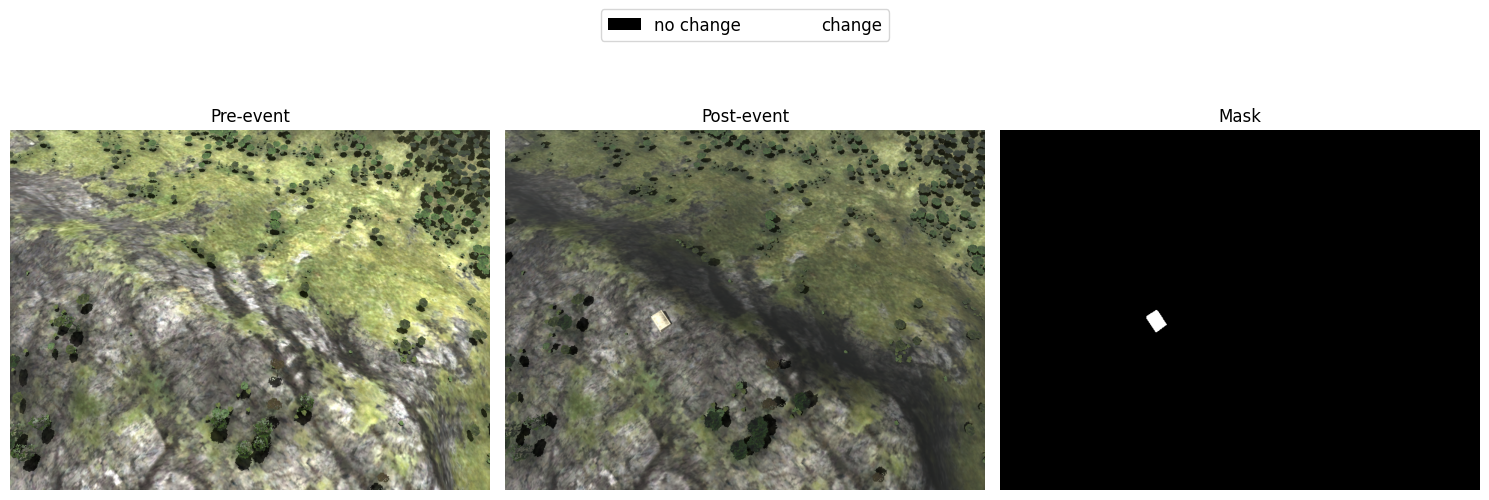

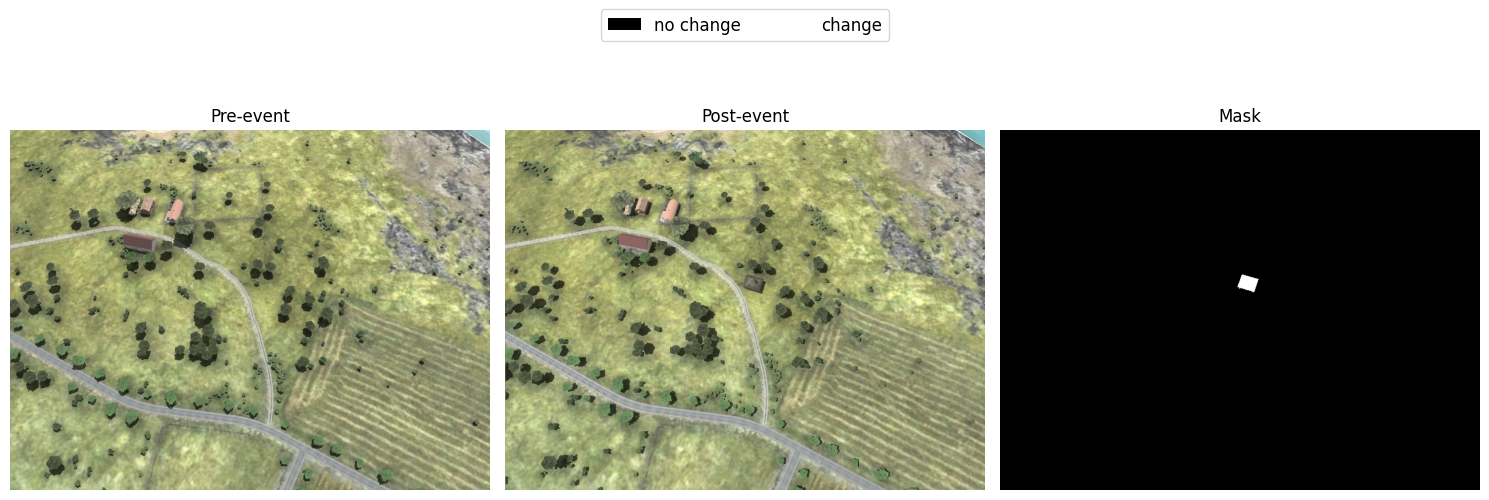

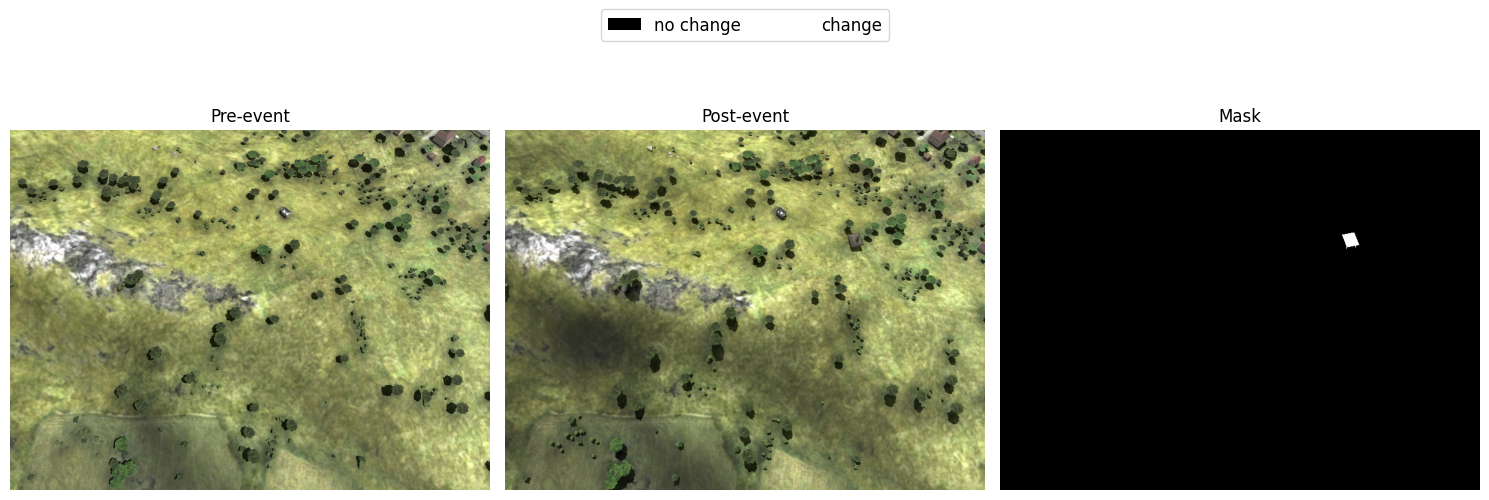

In [8]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [19]:
dataset.data_distribution_table()

,Number of pixels
no change,239796645.0
change,203355.0


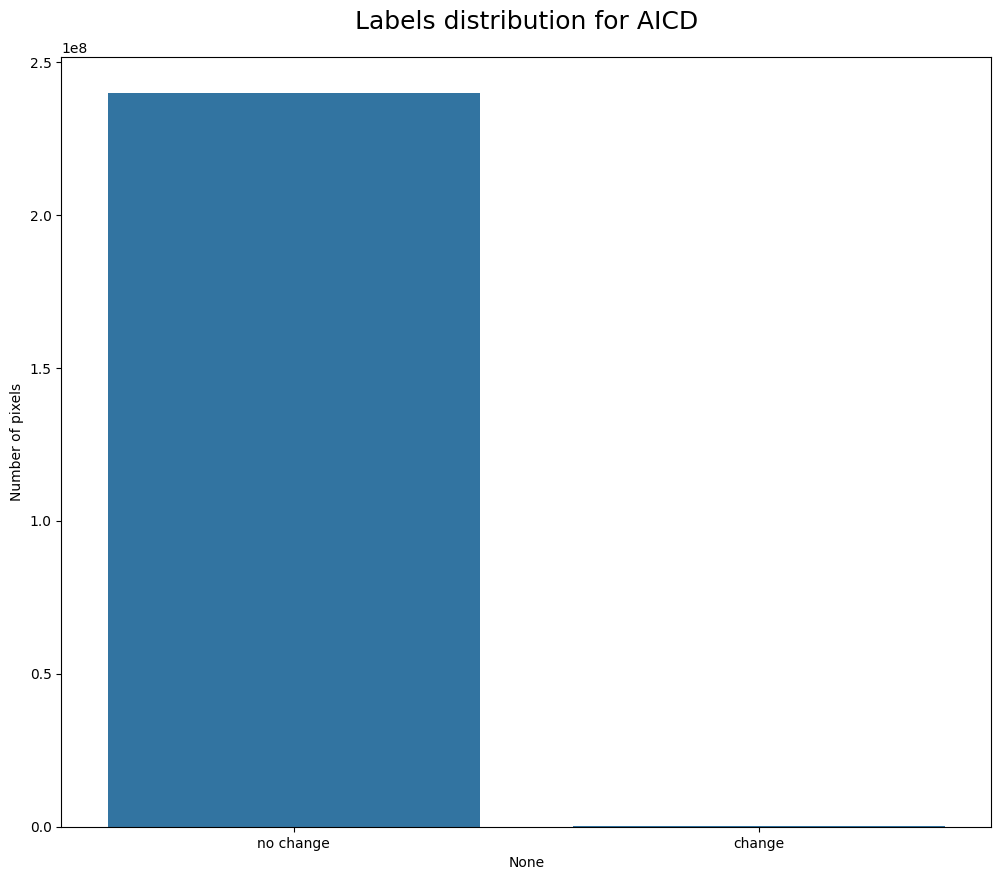

In [20]:
dataset.data_distribution_barchart();

## Load training and test data

In [13]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/aicd/AICDDataset/",
    "selection": "shadows",
    "csv_file": "/home/dragik/data/FAIR_EO/aicd/AICDDataset/aicd_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = AICDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/aicd/AICDDataset/",
    "selection": "shadows",
    "csv_file": "/home/dragik/data/FAIR_EO/aicd/AICDDataset/aicd_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = AICDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(300, 100)

## Create the model

In [14]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/aicd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [15]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-26 10:16:06,406 INFO Starting training.
training: 100%|██████████| 10/10 [01:11<00:00,  7.14s/it]
2026-01-26 10:17:17,867 INFO epoch: 1, loss:  0.26251
testing on train set: 100%|██████████| 10/10 [01:19<00:00,  7.91s/it]
2026-01-26 10:18:38,077 INFO Accuracy:0.9990533192952474, Accuracy per Class:[0.99862829 0.99947835], Precision Micro:0.9985673380124097, Precision Macro:0.499321761908395, Precision Weighted:0.9981983691562485, Precision per Class:[0.99864352 0.        ], Recall Micro:0.999538967973496, Recall Macro:0.49999236024247773, Recall Weighted:0.9995389679734958, Recall per Class:[0.99998472 0.        ], F1_score Micro:0.999052916753074, F1_score Macro:0.499656836070047, F1_score Weighted:0.99886821875469, F1_score per Class:[0.99931367 0.        ], IOU:0.9981076257421055, IOU mean:0.4993141428629557, IOU per Class:[0.99862829 0.        ]
training: 100%|██████████| 10/10 [01:20<00:00,  8.05s/it]
2026-01-26 10:19:58,542 INFO epoch: 2, loss:  0.23359
testing on train s

## Predictions

2026-01-26 12:24:00,295 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/aicd/checkpoint.pth.tar
2026-01-26 12:24:00,627 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/aicd/checkpoint.pth.tar at epoch 51


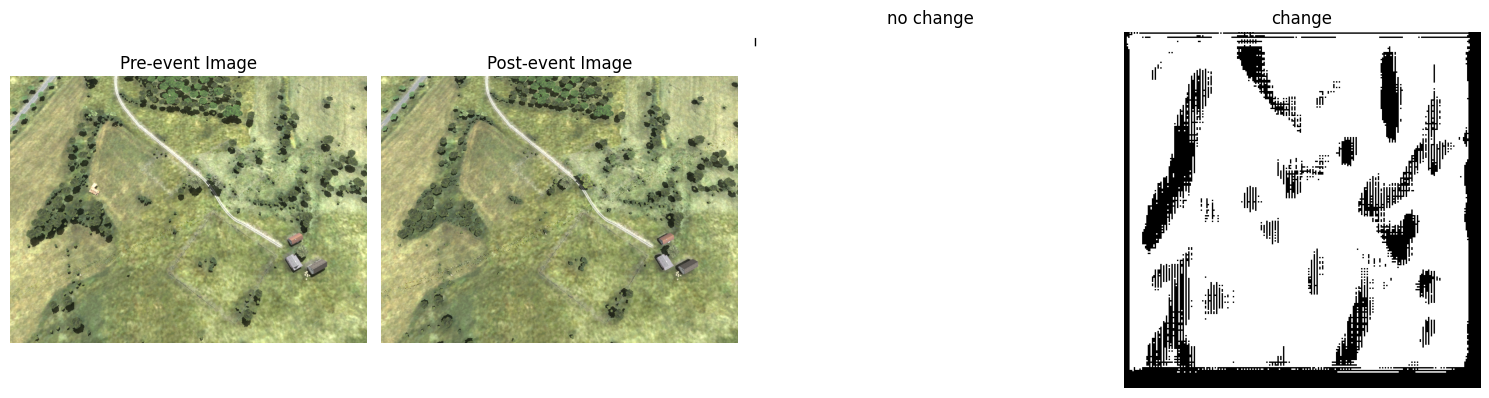

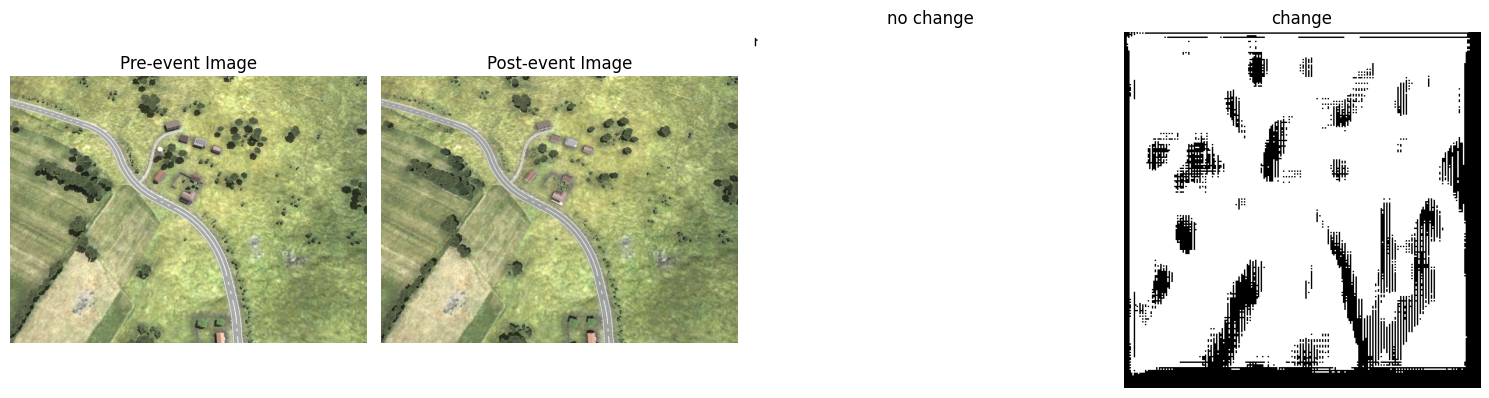

In [16]:
model_path = "/home/dragik/data/FAIR_EO/experiments/aicd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/aicd/AICDDataset/Images_Shadows/Scene0013_View01_moving.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/aicd/AICDDataset/Images_Shadows/Scene0013_View01_target.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/aicd/AICDDataset/Images_Shadows/Scene0074_View03_moving.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/aicd/AICDDataset/Images_Shadows/Scene0074_View03_target.png")
fig = model.predict_masks(image1, image2, labels, transform)